# Exp24 — Concept-parallel gender: language-agnostic gender feature vs shared concept + language-specific lookup

**The question.** At the decision position of a gender task, does the state carry (a) the *concept* of the noun, which each language then maps to its own grammatical gender (shared representation, language-specific computation), or (b) a *gender feature* in a format the other language can read (shared computation)?

**Why Exp21's gender result can't answer it.** Its donor nouns were index-paired, not translations. If the model reads the concept and looks gender up in the recipient's own lexicon, a donor noun's gender in the donor language says nothing about the recipient's output. So partial compat was uninterpretable.

**Design.** Every item is a concept with a noun and a grammatical gender in FR, ES, AR and HI (German is out: no cue-free agreement; EN/ZH have no gender). Concepts where languages agree and where they conflict are both present (sun: FR/ES masculine, AR feminine, HI masculine). Recipient = concept c in language L (label y = its gender in L). Donor = a prompt in language D, patched in at the decision position, layer by layer. Transfer is measured as movement toward *flipping L's answer*, divided by the movement from a same-language donor of opposite gender (the floor, as in Exp21).

| donor type | donor concept c' | gender feature predicts | concept lookup predicts |
|---|---|---|---|
| X | gender in D opposite to y, gender in L equals y | flip | no change |
| Y | gender in D equals y, gender in L opposite to y | no change | flip |
| Z (control) | opposite to y in both | flip | flip |
| W (control) | equals y in both | no change | no change |
| S | the same concept c in D (flips L's answer only if D and L conflict on c) | flip if conflict | no change |

`FL = frac_X - frac_Y`: +1 = feature transfer, -1 = lookup, 0 = neither or mixed. Z must be near 1 and W near 0 at the layers you read; if Z is not near 1, nothing transfers there and X/Y mean nothing.

**Representation, on the same concepts.** Wu Eq. 1 (matched translation vs non-matching concepts) is now valid, at the decision token and at the noun token, split by agree vs conflict concepts. A gender-direction readout applies D's masculine-to-feminine direction to L's states and reports whether it reads L's gender or D's on conflict concepts.

**Models.** BLOOM and Gemma-2 are both configured; edit `MODELS`. A baseline-accuracy gate per (model, language) is computed first (>= 0.75). Gemma's pretraining language mix is undisclosed, so data-share claims still rest on BLOOM.

All concept genders and surface forms were written by hand and need a native-speaker check; a wrong gender silently changes a donor's type. Cell 5 reports a median over late layers; Cell 6 shows every layer, because feature-vs-lookup can only be separated before the decision is formed. Untested on a GPU by me (no torch in my sandbox); item construction and the numpy analysis were tested with a mock tokenizer and synthetic data.

In [1]:
import os
for v in ("HTTP_PROXY","HTTPS_PROXY","ALL_PROXY","http_proxy","https_proxy","all_proxy"):
    os.environ.pop(v, None)              # drop the broken proxy
os.environ["HF_HUB_OFFLINE"] = "1"       # use only cached/local files, no network calls

In [2]:
# CELL 1 — config + data (edit MODELS / GPU_ID only)
import os
GPU_ID = 2
os.environ.setdefault("CUDA_VISIBLE_DEVICES", str(GPU_ID))
import json, math, random, itertools, warnings
from pathlib import Path
import numpy as np
OUT = Path("exp24_results"); OUT.mkdir(exist_ok=True)

MODELS = {"bloom-1b7": "bigscience/bloom-1b7", "bloom-7b1": "bigscience/bloom-7b1",
          "gemma-2-2b": "google/gemma-2-2b", "gemma-2-9b": "/home/models/gemma-2-9b"}
def prepend_bos(key): return "gemma" in key
LAYER_STRIDE, SEED, FLOOR_MIN_FRAC, ACC_GATE = 2, 0, 0.30, 0.75
KINDS = ("resid",)                       # add "attn", "mlp" to also patch component writes (slower; mostly invalid in Exp21)
LANGS = ["fr", "es", "ar", "hi"]; TYPES = ["X", "Y", "Z", "W", "S"]

FMT = {"fr": "Notre {n} est très", "es": "Mi {n} es muy", "ar": "{n}", "hi": "यह {n} बहुत"}      # no gendered determiner
ADJ = {"fr": [("petit","petite"),("grand","grande"),("joli","jolie")], "es": [("nuevo","nueva"),("viejo","vieja"),("bonito","bonita")],
       "ar": [("جديد","جديدة"),("كبير","كبيرة"),("جميل","جميلة")], "hi": [("बड़ा","बड़ी"),("अच्छा","अच्छी"),("छोटा","छोटी")]}
_rows = [   # concept, (fr), (es), (ar), (hi): (surface, gender)
 ("sun",("soleil","m"),("sol","m"),("الشمس","f"),("सूरज","m")), ("moon",("lune","f"),("luna","f"),("القمر","m"),("चाँद","m")),
 ("table",("table","f"),("mesa","f"),("الطاولة","f"),("मेज़","f")), ("book",("livre","m"),("libro","m"),("الكتاب","m"),("किताब","f")),
 ("house",("maison","f"),("casa","f"),("البيت","m"),("घर","m")), ("door",("porte","f"),("puerta","f"),("الباب","m"),("दरवाज़ा","m")),
 ("car",("voiture","f"),("coche","m"),("السيارة","f"),("गाड़ी","f")), ("water",("eau","f"),("agua","f"),("الماء","m"),("पानी","m")),
 ("night",("nuit","f"),("noche","f"),("الليل","m"),("रात","f")), ("day",("jour","m"),("día","m"),("اليوم","m"),("दिन","m")),
 ("hand",("main","f"),("mano","f"),("اليد","f"),("हाथ","m")), ("city",("ville","f"),("ciudad","f"),("المدينة","f"),("शहर","m")),
 ("tree",("arbre","m"),("árbol","m"),("الشجرة","f"),("पेड़","m")), ("word",("mot","m"),("palabra","f"),("الكلمة","f"),("शब्द","m")),
 ("bread",("pain","m"),("pan","m"),("الخبز","m"),("रोटी","f")), ("sea",("mer","f"),("mar","m"),("البحر","m"),("समुद्र","m")),
 ("river",("rivière","f"),("río","m"),("النهر","m"),("नदी","f")), ("window",("fenêtre","f"),("ventana","f"),("النافذة","f"),("खिड़की","f")),
 ("chair",("chaise","f"),("silla","f"),("الكرسي","m"),("कुर्सी","f")), ("key",("clé","f"),("llave","f"),("المفتاح","m"),("चाबी","f")),
 ("mountain",("montagne","f"),("montaña","f"),("الجبل","m"),("पहाड़","m")), ("letter",("lettre","f"),("carta","f"),("الرسالة","f"),("चिट्ठी","f")),
 ("bridge",("pont","m"),("puente","m"),("الجسر","m"),("पुल","m")), ("fire",("feu","m"),("fuego","m"),("النار","f"),("आग","f")),
 ("wind",("vent","m"),("viento","m"),("الريح","f"),("हवा","f")), ("ship",("bateau","m"),("barco","m"),("السفينة","f"),("जहाज़","m")),
 ("street",("rue","f"),("calle","f"),("الشارع","m"),("सड़क","f")), ("school",("école","f"),("escuela","f"),("المدرسة","f"),("स्कूल","m")),
]
CONCEPTS = {r[0]: dict(zip(LANGS, r[1:])) for r in _rows}
NAMES = list(CONCEPTS)
print("concepts:", len(NAMES))
for a, b in itertools.combinations(LANGS, 2):
    c = sum(CONCEPTS[n][a][1] != CONCEPTS[n][b][1] for n in NAMES); print(f"  {a}-{b}: {c} conflict / {len(NAMES) - c} agree")

concepts: 28
  fr-es: 4 conflict / 24 agree
  fr-ar: 17 conflict / 11 agree
  fr-hi: 13 conflict / 15 agree
  es-ar: 15 conflict / 13 agree
  es-hi: 15 conflict / 13 agree
  ar-hi: 14 conflict / 14 agree


In [3]:
# CELL 2 — helpers, items, donor selection (no GPU)
def enc(tok, text): return tok(text, add_special_tokens=False)["input_ids"]
def new_tokens(tok, prefix, cont):
    a, b = enc(tok, prefix), enc(tok, prefix + cont)
    return b[len(a):] if b[:len(a)] == a else None
def gen(c, L): return 0 if CONCEPTS[c][L][1] == "m" else 1
def prompt(L, c): return FMT[L].format(n=CONCEPTS[c][L][0])
def adj_of(c): return NAMES.index(c) % 3
def items_for(tok, L):
    out = []
    for c in NAMES:
        m, f = ADJ[L][adj_of(c)]; pr = prompt(L, c)
        if new_tokens(tok, pr, " " + m) and new_tokens(tok, pr, " " + f): out.append(c)
    return out

def pick_donors(c, L, D, rng):
    y = gen(c, L); others = [x for x in NAMES if x != c]
    cond = {"X": lambda x: gen(x, D) != y and gen(x, L) == y, "Y": lambda x: gen(x, D) == y and gen(x, L) != y,
            "Z": lambda x: gen(x, D) != y and gen(x, L) != y, "W": lambda x: gen(x, D) == y and gen(x, L) == y}
    out = {}
    for t, f in cond.items():
        pool = [x for x in others if f(x)]; out[t] = rng.choice(pool) if pool else None
    out["S"] = c
    return out
def pick_floor(c, L, rng):
    pool = [x for x in NAMES if x != c and gen(x, L) != gen(c, L)]; return rng.choice(pool)
def is_conflict(c, L, D): return gen(c, L) != gen(c, D)
print("helpers ok")

helpers ok


In [4]:
# CELL 3 — numpy analysis (no GPU)
def _nm(a, axis=0): 
    with warnings.catch_warnings():
        warnings.simplefilter("ignore"); return np.nanmean(a, axis=axis)

def type_transfer(P, Pb, m_clean, y, boots=300, seed=0):
    # P: {type: [n, n_layers] patched margins (NaN where no donor of that type exists)}; Pb: floor donor margins [n, n_layers]
    sgn = (1 - 2 * y)[:, None]; scale = np.abs(m_clean).mean()
    T = {t: (a - m_clean[:, None]) * sgn for t, a in P.items()}; Tb = (Pb - m_clean[:, None]) * sgn
    tb = Tb.mean(0); valid = tb >= FLOOR_MIN_FRAC * scale
    with np.errstate(divide="ignore", invalid="ignore"):
        frac = {t: np.where(valid, _nm(a) / tb, np.nan) for t, a in T.items()}
    fl = frac["X"] - frac["Y"]; rng, n, bs = np.random.default_rng(seed), len(y), []
    for _ in range(boots):
        ix = rng.integers(0, n, n); b_tb = Tb[ix].mean(0); v = b_tb >= FLOOR_MIN_FRAC * np.abs(m_clean[ix]).mean()
        with np.errstate(divide="ignore", invalid="ignore"): bs.append(np.where(v, (_nm(T["X"][ix]) - _nm(T["Y"][ix])) / b_tb, np.nan))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore"); lo, hi = np.nanpercentile(np.array(bs), [2.5, 97.5], axis=0)
    return dict(frac=frac, FL=fl, FL_lo=lo, FL_hi=hi, valid=valid, floor=tb)

def _unit(X): return X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-9)
def hub_by_group(SL, SD, conflict):
    # Wu Eq.1 on translation-matched concepts: matched cosine minus mean cosine to the other concepts, per layer; split by conflict / agree concepts
    n, nl, rows = SL.shape[0], SL.shape[1], []
    for l in range(nl):
        A, B = SL[:, l], SD[:, l]; ok = np.isfinite(A).all(1) & np.isfinite(B).all(1)
        S = _unit(np.nan_to_num(A)) @ _unit(np.nan_to_num(B)).T; m = np.diag(S); base = (S.sum(1) - m) / (n - 1); rel = m - base
        rows.append(dict(layer=l, rel=float(rel[ok].mean()) if ok.any() else np.nan,
                         rel_conflict=float(rel[ok & conflict].mean()) if (ok & conflict).any() else np.nan, rel_agree=float(rel[ok & ~conflict].mean()) if (ok & ~conflict).any() else np.nan))
    return rows

def gender_readout(SL, SD, yL, yD, conflict):
    # D's masculine->feminine direction (per-language centered) applied to L's states; accuracy against L's own gender on conflict / agree concepts
    nl, rows = SL.shape[1], []
    for l in range(nl):
        XL, XD = SL[:, l] - SL[:, l].mean(0), SD[:, l] - SD[:, l].mean(0)
        d = XD[yD == 1].mean(0) - XD[yD == 0].mean(0); pred = (XL @ d > 0).astype(int)
        rows.append(dict(layer=l, acc_L_conflict=float((pred == yL)[conflict].mean()) if conflict.any() else np.nan, acc_L_agree=float((pred == yL)[~conflict].mean()) if (~conflict).any() else np.nan))
    return rows
print("analysis functions ok")

analysis functions ok


In [5]:
# CELL 4 — run (GPU). Per model and recipient language: clean margins, states at the decision token and noun token, and patched margins for every donor type and language.
import torch, gc, time
from transformers import AutoTokenizer, AutoModelForCausalLM
dev = "cuda" if torch.cuda.is_available() else "cpu"

def get_modules(model):
    if hasattr(model, "transformer") and hasattr(model.transformer, "h"):
        bl = list(model.transformer.h); return dict(resid=bl, attn=[b.self_attention.dense for b in bl], mlp=[b.mlp.dense_4h_to_h for b in bl])
    bl = list(model.model.layers); return dict(resid=bl, attn=[b.self_attn.o_proj for b in bl], mlp=[b.mlp.down_proj for b in bl])
def patch_hook(p, vec):
    def hook(mod, inp, out):
        tup = isinstance(out, tuple); o = (out[0] if tup else out).clone(); o[:, p] = vec.to(o.dtype)
        return (o,) + tuple(out[1:]) if tup else o
    return hook
@torch.no_grad()
def margin(model, mods, tok, bos, prefix, c0t, c1t, patch=None):
    ids = bos + enc(tok, prefix); p = len(ids) - 1
    rows = [ids + c0t, ids + c1t]; T = max(map(len, rows)); pad = tok.pad_token_id if tok.pad_token_id is not None else 0
    inp = torch.tensor([r + [pad] * (T - len(r)) for r in rows], device=dev); att = torch.tensor([[1] * len(r) + [0] * (T - len(r)) for r in rows], device=dev)
    h = mods[patch[0]][patch[1]].register_forward_hook(patch_hook(p, patch[2])) if patch else None
    try: logits = model(input_ids=inp, attention_mask=att).logits
    finally:
        if h: h.remove()
    lp = []
    for r, ct in enumerate((c0t, c1t)):
        g = torch.log_softmax(logits[r, p:p + len(ct)].float(), -1); lp.append(sum(g[j, t].item() for j, t in enumerate(ct)))
    return lp[1] - lp[0]
@torch.no_grad()
def capture(model, mods, tok, bos, prefix, extra_pos=None):
    # states at the last prefix token (all kinds) and, optionally, at another position (resid only)
    ids = bos + enc(tok, prefix); p = len(ids) - 1; nl = len(mods["resid"]); store = {k: [None] * nl for k in KINDS}; alt = [None] * nl; hs = []
    for k in KINDS:
        for li, m in enumerate(mods[k]):
            def hk(mod, inp, out, k=k, li=li):
                o = out[0] if isinstance(out, tuple) else out; store[k][li] = o[0, p].detach()
            hs.append(m.register_forward_hook(hk))
    if extra_pos is not None:
        for li, m in enumerate(mods["resid"]):
            def hk2(mod, inp, out, li=li):
                o = out[0] if isinstance(out, tuple) else out; alt[li] = o[0, extra_pos + len(bos)].detach()
            hs.append(m.register_forward_hook(hk2))
    try: model(input_ids=torch.tensor([ids], device=dev))
    finally:
        for h in hs: h.remove()
    res = {k: torch.stack(v) for k, v in store.items()}
    res["noun"] = torch.stack(alt) if extra_pos is not None else None
    return res
def noun_index(tok, prefix, noun):
    # index (without bos) of the last token of the noun, if tokenizing the prefix up to the noun is a prefix of tokenizing the full prefix
    cut = prefix.index(noun) + len(noun); a, b = enc(tok, prefix[:cut]), enc(tok, prefix)
    return len(a) - 1 if b[:len(a)] == a else None

for key, path in MODELS.items():
    tok = AutoTokenizer.from_pretrained(path); bos = [tok.bos_token_id] if prepend_bos(key) else []
    model = AutoModelForCausalLM.from_pretrained(path, torch_dtype=torch.bfloat16).to(dev).eval(); mods = get_modules(model); nl = len(mods["resid"])
    LAYERS = sorted(set(list(range(0, nl, LAYER_STRIDE)) + [nl - 1])); cache = {}
    def cap(L, c):
        pr = prompt(L, c)
        if (L, c) not in cache:
            ni = noun_index(tok, pr, CONCEPTS[c][L][0]); cache[(L, c)] = capture(model, mods, tok, bos, pr, extra_pos=ni)
        return cache[(L, c)]
    for L in LANGS:
        f = OUT / f"{key}__{L}.npz"
        if f.exists(): print("cached", f.name); continue
        cs = items_for(tok, L); n = len(cs); t0 = time.time(); rng = random.Random(SEED)
        y = np.array([gen(c, L) for c in cs]); mc = np.zeros(n);
        S_last = None
        P = {(D, t, k): np.full((n, len(LAYERS)), np.nan) for D in LANGS if D != L for t in TYPES for k in KINDS}; Pb = {k: np.zeros((n, len(LAYERS))) for k in KINDS}
        for i, c in enumerate(cs):
            m_, f_ = ADJ[L][adj_of(c)]; pr = prompt(L, c); c0t, c1t = new_tokens(tok, pr, " " + m_), new_tokens(tok, pr, " " + f_)
            mc[i] = margin(model, mods, tok, bos, pr, c0t, c1t); cl = cap(L, c)
            if S_last is None: Hd = cl["resid"].shape[-1]; S_last = np.zeros((n, nl, Hd), np.float32); S_noun = np.full((n, nl, Hd), np.nan, np.float32)
            S_last[i] = cl["resid"].float().cpu().numpy()
            if cl["noun"] is not None: S_noun[i] = cl["noun"].float().cpu().numpy()
            fl = cap(L, pick_floor(c, L, rng))
            for k in KINDS:
                for j, l in enumerate(LAYERS): Pb[k][i, j] = margin(model, mods, tok, bos, pr, c0t, c1t, patch=(k, l, fl[k][l]))
            for D in LANGS:
                if D == L: continue
                dn = pick_donors(c, L, D, rng)
                for t, cp in dn.items():
                    if cp is None: continue
                    dcap = cap(D, cp)
                    for k in KINDS:
                        for j, l in enumerate(LAYERS): P[(D, t, k)][i, j] = margin(model, mods, tok, bos, pr, c0t, c1t, patch=(k, l, dcap[k][l]))
        np.savez(f, concepts=np.array(cs), y=y, m_clean=mc, layers=np.array(LAYERS), S_last=S_last, S_noun=S_noun, **{f"Pb_{k}": Pb[k] for k in KINDS}, **{f"P_{D}_{t}_{k}": v for (D, t, k), v in P.items()})
        print(f"saved {f.name} n={n} clean acc={(((mc > 0).astype(int)) == y).mean():.2f} {time.time() - t0:.0f}s")
    del model; gc.collect(); torch.cuda.empty_cache()

/home/anwoy/miniconda3/envs/ke/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
`torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 293/293 [00:01<00:00, 196.76it/s]


cached bloom-1b7__fr.npz
cached bloom-1b7__es.npz
cached bloom-1b7__ar.npz
cached bloom-1b7__hi.npz


Loading weights: 100%|██████████| 365/365 [00:07<00:00, 48.89it/s] 


cached bloom-7b1__fr.npz
cached bloom-7b1__es.npz
cached bloom-7b1__ar.npz
cached bloom-7b1__hi.npz


Loading weights: 100%|██████████| 288/288 [00:00<00:00, 1923.34it/s]


cached gemma-2-2b__fr.npz
cached gemma-2-2b__es.npz
cached gemma-2-2b__ar.npz
cached gemma-2-2b__hi.npz


Loading weights: 100%|██████████| 464/464 [00:00<00:00, 818.98it/s]


cached gemma-2-9b__fr.npz
cached gemma-2-9b__es.npz
cached gemma-2-9b__ar.npz
cached gemma-2-9b__hi.npz


In [6]:
# CELL 5 — analysis (no GPU): gate, feature-vs-lookup index, controls, hub similarity by agree/conflict, gender readout
import pandas as pd
rows_t, rows_h, rows_g, rows_a = [], [], [], []
for key in sorted({f.stem.split("__")[0] for f in OUT.glob("*.npz")}):
    Z = {L: np.load(OUT / f"{key}__{L}.npz") for L in LANGS if (OUT / f"{key}__{L}.npz").exists()}
    for L, z in Z.items():
        y, mc, layers = z["y"], z["m_clean"], z["layers"]; acc = float(((mc > 0).astype(int) == y).mean()); rows_a.append(dict(model=key, lang=L, n=len(y), clean_acc=round(acc, 2), PASS=acc >= ACC_GATE))
        cs = list(z["concepts"]); half = len(layers) // 2
        for D in LANGS:
            if D == L or f"P_{D}_X_resid" not in z.files: continue
            conf = np.array([is_conflict(c, L, D) for c in cs])
            P = {t: z[f"P_{D}_{t}_resid"] for t in TYPES}
            Pc = dict(P); Pc["S_conflict"] = np.where(conf[:, None], P["S"], np.nan); Pc["S_agree"] = np.where(~conf[:, None], P["S"], np.nan); Pc.pop("S")
            Pc["X"], Pc["Y"] = P["X"], P["Y"]
            tt = type_transfer(Pc, z["Pb_resid"], mc, y)
            r = dict(model=key, lang=L, donor=D, gate=acc >= ACC_GATE, valid_late=int(tt["valid"][half:].sum()), n=len(y), n_conflict=int(conf.sum()))
            for t, v in tt["frac"].items(): r[t] = round(float(np.nanmedian(v[half:])), 2) if np.isfinite(v[half:]).any() else np.nan
            r["FL"] = round(float(np.nanmedian(tt["FL"][half:])), 2) if np.isfinite(tt["FL"][half:]).any() else np.nan
            r["FL_lo"] = round(float(np.nanmedian(tt["FL_lo"][half:])), 2) if np.isfinite(tt["FL_lo"][half:]).any() else np.nan
            r["FL_hi"] = round(float(np.nanmedian(tt["FL_hi"][half:])), 2) if np.isfinite(tt["FL_hi"][half:]).any() else np.nan
            rows_t.append(r)
            if D in Z:   # representation on concepts valid in both languages
                zd = Z[D]; both = [c for c in cs if c in list(zd["concepts"])]; iL = [cs.index(c) for c in both]; iD = [list(zd["concepts"]).index(c) for c in both]
                cf = np.array([is_conflict(c, L, D) for c in both])
                for tag, SL, SD in (("decision", z["S_last"][iL], zd["S_last"][iD]), ("noun", z["S_noun"][iL], zd["S_noun"][iD])):
                    for hr in hub_by_group(SL, SD, cf): hr.update(model=key, lang=L, donor=D, pos=tag); rows_h.append(hr)
                for gr in gender_readout(z["S_last"][iL], zd["S_last"][iD], y[iL], zd["y"][iD], cf): gr.update(model=key, lang=L, donor=D); rows_g.append(gr)
df_a, df_t, df_h, df_g = pd.DataFrame(rows_a), pd.DataFrame(rows_t), pd.DataFrame(rows_h), pd.DataFrame(rows_g)
pd.set_option("display.width", 250)
print("GATE (clean accuracy of the gender choice):\n", df_a.to_string(index=False))
print("\nTRANSFER (fraction of a same-language gender flip; median over valid late layers). Controls: Z should be ~1, W ~0.")
print("Prediction: feature transfer -> X~1, Y~0, S_conflict~1 (FL~+1); concept lookup -> X~0, Y~1, S_conflict~0 (FL~-1)")
print(df_t[["model","lang","donor","gate","valid_late","n_conflict","X","Y","Z","W","S_conflict","S_agree","FL","FL_lo","FL_hi"]].to_string(index=False))
if len(df_h):
    dd = df_h.copy(); mid = dd.groupby(["model", "lang", "donor", "pos"]).apply(lambda g: g.iloc[int(.3 * len(g)):int(.85 * len(g)) + 1][["rel", "rel_conflict", "rel_agree"]].mean()).round(3)
    print("\nHUB SIMILARITY (Wu Eq.1, mean over middle layers) by position; compare conflict vs agree concepts:\n", mid.to_string())
if len(df_g):
    gg = df_g.groupby(["model", "lang", "donor"]).apply(lambda g: g.iloc[int(.5 * len(g)):][["acc_L_conflict", "acc_L_agree"]].mean()).round(2)
    print("\nGENDER READOUT: D's gender direction applied to L's decision-token states; accuracy against L's own gender (conflict concepts: below 0.5 means it reads D's gender)\n", gg.to_string())
df_a.to_csv(OUT / "gate.csv", index=False); df_t.to_csv(OUT / "transfer_summary.csv", index=False); df_h.to_csv(OUT / "hub_per_layer.csv", index=False); df_g.to_csv(OUT / "gender_readout_per_layer.csv", index=False)

GATE (clean accuracy of the gender choice):
      model lang  n  clean_acc  PASS
 bloom-1b7   fr 28       1.00  True
 bloom-1b7   es 28       1.00  True
 bloom-1b7   ar 28       0.96  True
 bloom-1b7   hi 28       1.00  True
 bloom-7b1   fr 28       1.00  True
 bloom-7b1   es 28       1.00  True
 bloom-7b1   ar 28       1.00  True
 bloom-7b1   hi 28       0.96  True
gemma-2-2b   fr 28       1.00  True
gemma-2-2b   es 28       0.96  True
gemma-2-2b   ar 28       0.93  True
gemma-2-2b   hi 28       1.00  True
gemma-2-9b   fr 28       1.00  True
gemma-2-9b   es 28       1.00  True
gemma-2-9b   ar 28       0.96  True
gemma-2-9b   hi 28       0.96  True

TRANSFER (fraction of a same-language gender flip; median over valid late layers). Controls: Z should be ~1, W ~0.
Prediction: feature transfer -> X~1, Y~0, S_conflict~1 (FL~+1); concept lookup -> X~0, Y~1, S_conflict~0 (FL~-1)
     model lang donor  gate  valid_late  n_conflict     X     Y     Z     W  S_conflict  S_agree    FL  FL_lo  FL_

/tmp/ipykernel_1745118/129581838.py:35: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  dd = df_h.copy(); mid = dd.groupby(["model", "lang", "donor", "pos"]).apply(lambda g: g.iloc[int(.3 * len(g)):int(.85 * len(g)) + 1][["rel", "rel_conflict", "rel_agree"]].mean()).round(3)
/tmp/ipykernel_1745118/129581838.py:38: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  gg = df_g.groupby(["model", "lang", "donor"]).apply(lambda g

per-layer table saved to per_layer_by_type.csv; columns: floor = same-language flip transfer / mean|clean margin|; X,Y,Z,W,S_* = fraction of a flip (NaN where floor < threshold); FL = X - Y


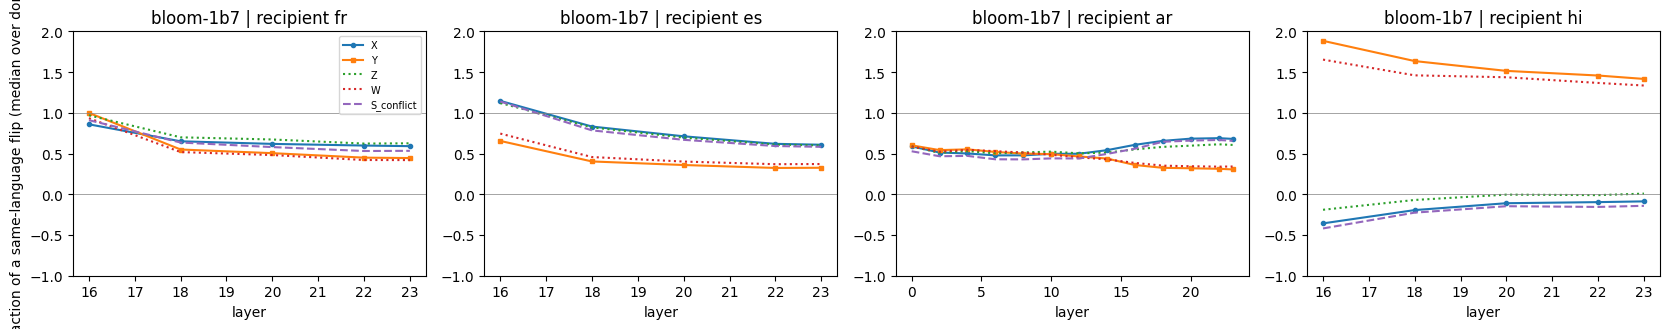

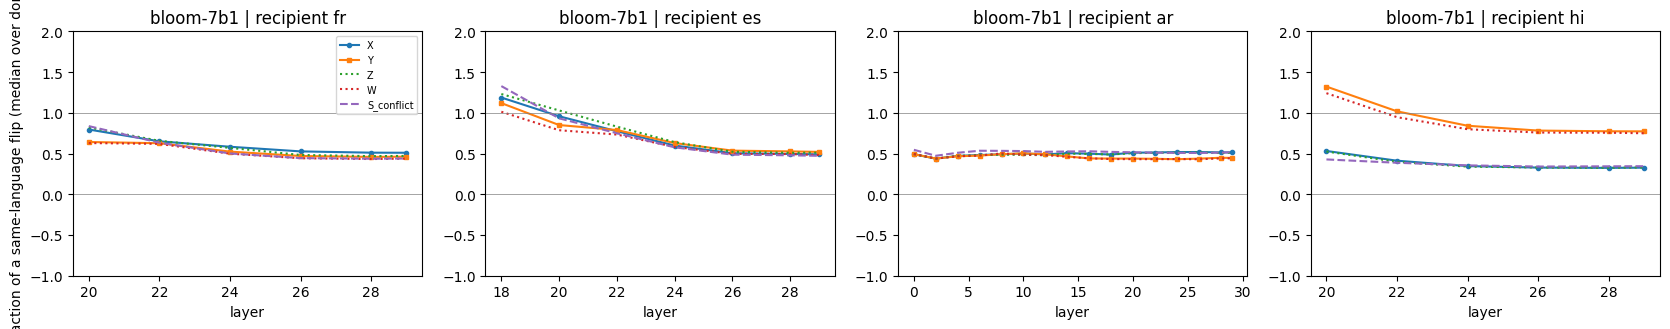

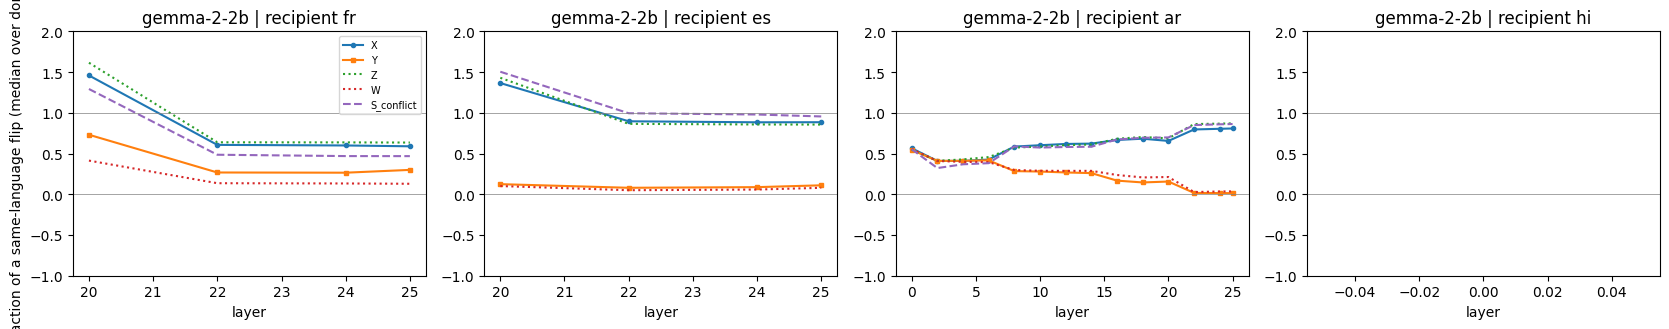

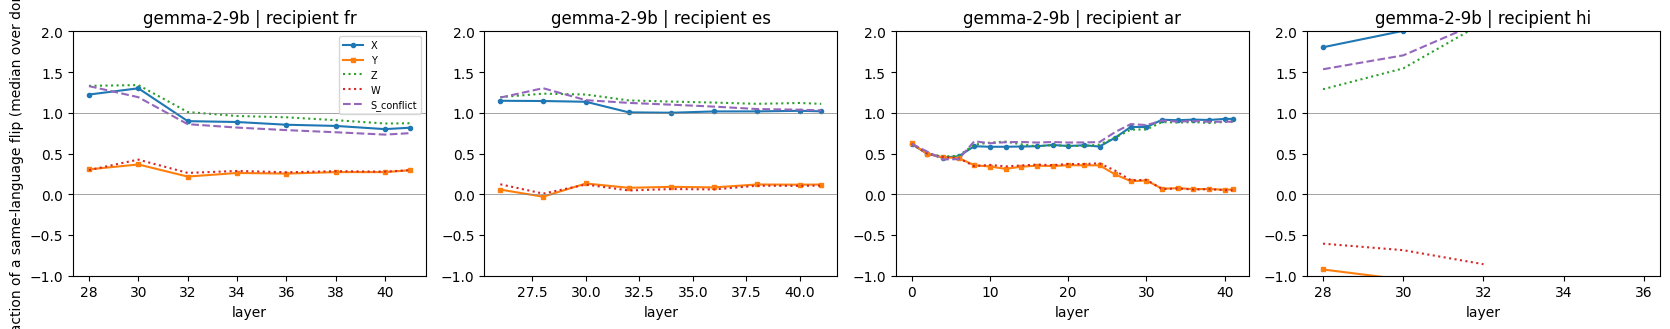

In [7]:
# CELL 6 — per-layer view (no GPU): where along depth does a donor flip the answer, by donor type?
# The summary above takes the median over late layers, where the masculine/feminine decision may already be formed. Lookup vs feature is only separable BEFORE that.
import pandas as pd, matplotlib.pyplot as plt
FLOOR_MIN_FRAC = 0.60      # stricter than the 0.30 used above: ratios blow up when the same-language floor is small (HI rows had values of 3 to 6)
rows_p = []
for key in sorted({f.stem.split("__")[0] for f in OUT.glob("*.npz")}):
    for L in LANGS:
        fz = OUT / f"{key}__{L}.npz"
        if not fz.exists(): continue
        z = np.load(fz); y, mc, layers, cs = z["y"], z["m_clean"], z["layers"], list(z["concepts"]); per_D = []
        for D in LANGS:
            if D == L or f"P_{D}_X_resid" not in z.files: continue
            conf = np.array([is_conflict(c, L, D) for c in cs]); P = {t: z[f"P_{D}_{t}_resid"] for t in TYPES}
            P["S_conflict"] = np.where(conf[:, None], P["S"], np.nan); P["S_agree"] = np.where(~conf[:, None], P["S"], np.nan); P.pop("S")
            tt = type_transfer(P, z["Pb_resid"], mc, y); per_D.append({**tt["frac"], "FL": tt["FL"], "floor": tt["floor"] / np.abs(mc).mean()})
        if not per_D: continue
        for j, l in enumerate(layers):
            r = dict(model=key, lang=L, layer=int(l), floor=float(np.nanmedian([d["floor"][j] for d in per_D])), n_donors_valid=int(sum(np.isfinite(d["FL"][j]) for d in per_D)))
            for t in ("X", "Y", "Z", "W", "S_conflict", "S_agree", "FL"): r[t] = float(np.nanmedian([d[t][j] for d in per_D])) if any(np.isfinite(d[t][j]) for d in per_D) else np.nan
            rows_p.append(r)
df_p = pd.DataFrame(rows_p); df_p.to_csv(OUT / "per_layer_by_type.csv", index=False)
print("per-layer table saved to per_layer_by_type.csv; columns: floor = same-language flip transfer / mean|clean margin|; X,Y,Z,W,S_* = fraction of a flip (NaN where floor < threshold); FL = X - Y")
for key in df_p.model.unique():
    fig, axs = plt.subplots(1, len(LANGS), figsize=(4.2 * len(LANGS), 3.4), squeeze=False)
    for ax, L in zip(axs[0], LANGS):
        d = df_p[(df_p.model == key) & (df_p.lang == L)]
        for t, st in (("X", "-o"), ("Y", "-s"), ("Z", ":"), ("W", ":"), ("S_conflict", "--")): ax.plot(d.layer, d[t], st, ms=3, label=t)
        ax.axhline(0, color="gray", lw=.5); ax.axhline(1, color="gray", lw=.5); ax.set_title(f"{key} | recipient {L}"); ax.set_xlabel("layer"); ax.set_ylim(-1, 2)
    axs[0][0].set_ylabel("fraction of a same-language flip (median over donors)"); axs[0][0].legend(fontsize=7)
    plt.tight_layout(); plt.savefig(OUT / f"per_layer_{key}.png", dpi=140); plt.show()